<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/04_pytorch_custom_datasets_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. PyTorch Custom Datasets Exercises Template

Welcome to the 04. PyTorch Custom Datasets exercise template.

The best way to practice PyTorch code is to write more PyTorch code.

So read the original notebook and try to complete the exercises by writing code where it's required.

Feel free to reference the original resources whenever you need but should practice writing all of the code yourself.

## Resources

1. These exercises/solutions are based on [notebook 04 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/04_pytorch_custom_datasets/).
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/vsFMF9wqWx0).
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Fri Oct 16 10:59:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.08              KMD Version: 616.92        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    On  |   00000000:01:00.0 Off |                  N/A |
| N/A   41C    P0              9W /   95W |       0MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [27]:
# Import torch
import torch
from torch import nn

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# Setup device agnostic code
# device = "cuda" if torch.cuda.is_available() else "cpu"
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
device

2.11.0+cu128


device(type='cuda')

## 1. Our models are underperforming (not fitting the data well). What are 3 methods for preventing underfitting? Write them down and explain each with a sentence.

1. Train for more epochs 
2. Change the learning rate 
3. Collect more train data

## 2. Recreate the data loading functions we built in [sections 1, 2, 3 and 4 of notebook 04](https://www.learnpytorch.io/04_pytorch_custom_datasets/). You should have train and test `DataLoader`'s ready to use.

In [3]:
# 1. Get data
import requests
import zipfile
from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it... 
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)
    
    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...") 
        zip_ref.extractall(image_path)

data/pizza_steak_sushi directory exists.


In [4]:
# 2. Become one with the data
import os
def walk_through_dir(dir_path):
  """Walks through dir_path returning file counts of its contents."""
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [5]:
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data/pizza_steak_sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directories and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 0 directories and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 0 directories and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directories and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 0 directories and 19 images in 'data/pizza_steak_sushi/test/steak'.
There are 0 directories and 31 images in 'data/pizza_steak_sushi/test/sushi'.


In [6]:
# Setup train and testing paths

train_dir = image_path / 'train'
test_dir = image_path / 'test'

In [7]:
# Visualize an image

from PIL import Image
import random

random.seed(42)

all_image_path = list(image_path.glob("*/*/*.jpg"))

random_image_path = random.choice(all_image_path)

random_image = Image.open(random_image_path)

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

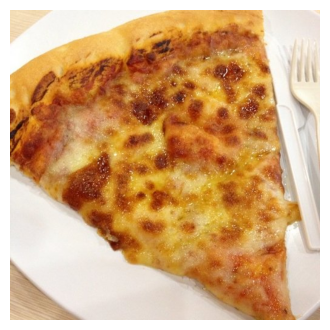

In [8]:
# Do the image visualization with matplotlib
import matplotlib.pyplot as plt

plt.figure(figsize=(4,7))
plt.imshow(random_image)
plt.axis(False)

We've got some images in our folders.

Now we need to make them compatible with PyTorch by:
1. Transform the data into tensors.
2. Turn the tensor data into a `torch.utils.data.Dataset` and later a `torch.utils.data.DataLoader`.

In [9]:
# 3.1 Transforming data with torchvision.transforms


In [10]:
# Write transform for turning images into tensors
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [11]:
torch.Tensor.permute

<method 'permute' of 'torch._C.TensorBase' objects>

In [12]:
# Write a function to plot transformed images

from PIL import Image


def plot_image(image_path: Path, transform: transforms.Compose = transform):

    img: torch.Tensor = transform(Image.open(image_path))

    plt.figure(figsize=(4,7))
    plt.imshow(img.permute(1, 2, 0))
    plt.axis(False)



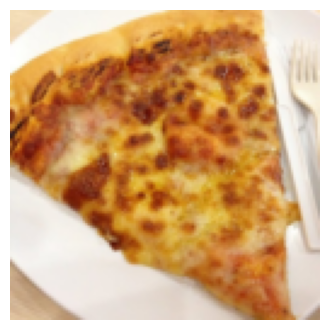

In [13]:
plot_image(random_image_path)

### Load image data using `ImageFolder`

In [14]:
# Use ImageFolder to create dataset(s)
from torchvision.datasets import ImageFolder

train_data = ImageFolder(
    root = train_dir,
    transform = transform
)

test_data = ImageFolder(
    root = test_dir,
    transform = transform
)

In [15]:
# Get class names as a list
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [16]:
# Can also get class names as a dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [17]:
# Check the lengths of each dataset
len(train_data), len(test_data)

(225, 75)

In [18]:
# Turn train and test Datasets into DataLoaders
from torch.utils.data import DataLoader
import os

BATCH_SIZE: int = 32
train_dataloader = DataLoader(
    dataset = train_data,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count() or 0,
    shuffle = True
)


test_dataloader = DataLoader(
    dataset = test_data,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count() or 0,
)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x75b636084ad0>,
 <torch.utils.data.dataloader.DataLoader at 0x75b636084c20>)

In [19]:
# How many batches of images are in our data loaders?

len(train_dataloader), len(test_dataloader)

(8, 3)

## 3. Recreate `model_0` we built in section 7 of notebook 04.

In [54]:
# I wont make the exact same, I will modify it a bit
from torch import nn
class ModifiedTinyVGG(nn.Module):

    def __init__(self,
                 in_channels: int,
                 hidden_units: int,
                 output_units: int):

        super().__init__()

        self.conv1 = nn.Sequential(

            nn.Conv2d(
                in_channels = in_channels,
                out_channels = hidden_units,
                kernel_size = 3,
                stride = 1,
                padding = 1
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels = hidden_units,
                out_channels = hidden_units,
                kernel_size = 3,
                stride = 1,
                padding = 1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size = 2,
                stride = 2
            )
        )

        self.conv2 =  nn.Sequential(

            nn.Conv2d(
                in_channels = hidden_units,
                out_channels = hidden_units,
                kernel_size = 3,
                stride = 1,
                padding = 1
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels = hidden_units,
                out_channels = hidden_units,
                kernel_size = 3,
                stride = 1,
                padding = 1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size = 2,
                stride = 2
            )
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features = hidden_units * 32 * 32,
                out_features = output_units
            )
        )

        self.layers = nn.Sequential(
            self.conv1,
            self.conv2,
            self.classifier
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)

model_0 = ModifiedTinyVGG(
    in_channels = 3,
    hidden_units = 10,
    output_units = len(class_names)
)


In [21]:
images = next(iter(train_dataloader))
model_0(images[0])

tensor([[ 0.0057,  0.0642, -0.0396],
        [ 0.0037,  0.0603, -0.0374],
        [ 0.0048,  0.0626, -0.0367],
        [ 0.0027,  0.0512, -0.0323],
        [ 0.0026,  0.0574, -0.0359],
        [ 0.0057,  0.0598, -0.0345],
        [ 0.0031,  0.0573, -0.0398],
        [ 0.0046,  0.0572, -0.0377],
        [ 0.0036,  0.0580, -0.0375],
        [ 0.0029,  0.0574, -0.0357],
        [ 0.0063,  0.0658, -0.0375],
        [ 0.0059,  0.0578, -0.0353],
        [ 0.0058,  0.0578, -0.0396],
        [ 0.0071,  0.0609, -0.0371],
        [ 0.0025,  0.0529, -0.0352],
        [ 0.0027,  0.0673, -0.0363],
        [ 0.0014,  0.0585, -0.0386],
        [ 0.0077,  0.0618, -0.0368],
        [ 0.0052,  0.0542, -0.0369],
        [ 0.0029,  0.0600, -0.0408],
        [ 0.0031,  0.0557, -0.0361],
        [ 0.0039,  0.0588, -0.0371],
        [ 0.0031,  0.0628, -0.0376],
        [ 0.0017,  0.0537, -0.0361],
        [ 0.0035,  0.0768, -0.0465],
        [ 0.0027,  0.0514, -0.0313],
        [ 0.0031,  0.0620, -0.0339],
 

## 4. Create training and testing functions for `model_0`.

In [53]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device = device
              ):
  
  model.to(device)
  # Put the model in train mode
  model.train()

  # Setup train loss and train accuracy values
  train_loss, train_acc = 0, 0

  # Loop through data loader and data batches
  for batch, (X, y) in enumerate(dataloader):
 
    # Send data to target device
    X = X.to(device)
    y = y.to(device)

    # 1. Forward pass

    y_logits = model(X)
    
    # 2. Calculate and accumulate loss

    loss = loss_fn(y_logits, y)

    train_loss += loss.item()

    # 3. Optimizer zero grad 

    optimizer.zero_grad()
    

    # 4. Loss backward 
    
    loss.backward()

    # 5. Optimizer step

    optimizer.step()
    

    # Calculate and accumualte accuracy metric across all batches
    train_acc += (torch.sum(torch.argmax(y_logits, dim=1) == y) / len(y)).item()
   

  # Adjust metrics to get average loss and average accuracy per batch
  train_loss /= len(dataloader)
  train_acc /= len(dataloader)

  print(f"Train Loss: {train_loss :.2f} | Train Accuracy: {train_acc: .2%}")

  return train_loss, train_acc

In [55]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device = device):
  

  model.to(device)
  # Put model in eval mode
  model.eval()

  # Setup the test loss and test accuracy values
  test_loss, test_acc = 0, 0

  # Turn on inference context manager
  with torch.inference_mode():
  
    # Loop through DataLoader batches
    for batch, (X, y) in enumerate(dataloader):
    
      # Send data to target device

      X = X.to(device)
      y = y.to(device)
      

      # 1. Forward pass

      y_logits = model(X)
      

      # 2. Calculuate and accumulate loss
      
      loss = loss_fn(y_logits, y)

      test_loss += loss.item()

      # Calculate and accumulate accuracy

      test_acc += (torch.sum(torch.argmax(y_logits , dim=1) == y) / len(y)).item()

    
  # Adjust metrics to get average loss and accuracy per batch

  test_loss /= len(dataloader)
  test_acc /= len(dataloader)


  print(f"Test Loss: {test_loss :.2f} | Test Accuracy: {test_acc: .2%}")

  return test_loss, test_acc

In [38]:
from tqdm.auto import tqdm

def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
  
  # Create results dictionary
  results = {"train_loss": [],
             "train_acc": [],
             "test_loss": [],
             "test_acc": []}

  # Loop through the training and testing steps for a number of epochs
  for epoch in tqdm(range(epochs)):
    # Train step
    train_loss, train_acc = train_step(model=model, 
                                       dataloader=train_dataloader,
                                       loss_fn=loss_fn,
                                       optimizer=optimizer,
                                       device=device)
    # Test step
    test_loss, test_acc = test_step(model=model, 
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn,
                                    device=device)
    
    # Print out what's happening
    print(f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
    )

    # Update the results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

  # Return the results dictionary
  return results

## 5. Try training the model you made in exercise 3 for 5, 20 and 50 epochs, what happens to the results?
* Use `torch.optim.Adam()` with a learning rate of 0.001 as the optimizer. 

In [40]:
# Train for 5 epochs
torch.manual_seed(42)
torch.cuda.manual_seed(42)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model_0.parameters(), 
                             lr=0.001)

In [47]:
train(
    model_0,
    train_dataloader,
    test_dataloader,
    optimizer,
    loss_fn,
    epochs=5,
)

  0%|          | 0/5 [00:00<?, ?it/s]

Train Loss: 1.11 | Train Accuracy:  30.47%


 20%|██        | 1/5 [00:01<00:05,  1.47s/it]

Test Loss: 1.08 | Train Accuracy:  26.04%
Epoch: 1 | train_loss: 1.1087 | train_acc: 0.3047 | test_loss: 1.0806 | test_acc: 0.2604
Train Loss: 1.08 | Train Accuracy:  41.02%


 40%|████      | 2/5 [00:02<00:03,  1.32s/it]

...

 80%|████████  | 4/5 [00:05<00:01,  1.27s/it]

Test Loss: 1.09 | Train Accuracy:  30.21%
Epoch: 4 | train_loss: 1.0806 | train_acc: 0.3945 | test_loss: 1.0913 | test_acc: 0.3021
Train Loss: 1.06 | Train Accuracy:  44.92%


100%|██████████| 5/5 [00:06<00:00,  1.25s/it]

Test Loss: 1.03 | Train Accuracy:  37.22%
Epoch: 5 | train_loss: 1.0584 | train_acc: 0.4492 | test_loss: 1.0310 | test_acc: 0.3722


{'train_loss': [1.1086746901273727,
  1.0776638686656952,
  1.0933613777160645,
  1.0806431621313095,
  1.0583885163068771],
 'train_acc': [0.3046875, 0.41015625, 0.41796875, 0.39453125, 0.44921875],
 'test_loss': [1.0806380311648052,
  1.0132871468861897,
  1.0405797561009724,
  1.0913199385007222,
  1.0309687852859497],
 'test_acc': [0.2604166666666667,
  0.5833333333333334,
  0.4725378751754761,
  0.3020833333333333,
  0.37215909361839294]}

In [48]:
# Train for 20 epochs
torch.manual_seed(42)
torch.cuda.manual_seed(42)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), 
                             lr=0.001)

In [49]:

train(
    model_0,
    train_dataloader,
    test_dataloader,
    optimizer,
    loss_fn,
    epochs=20,
)

  0%|          | 0/20 [00:00<?, ?it/s]

Train Loss: 0.96 | Train Accuracy:  59.38%


  5%|▌         | 1/20 [00:01<00:28,  1.49s/it]

Test Loss: 1.14 | Train Accuracy:  32.29%
Epoch: 1 | train_loss: 0.9617 | train_acc: 0.5938 | test_loss: 1.1416 | test_acc: 0.3229
Train Loss: 0.95 | Train Accuracy:  46.48%


 10%|█         | 2/20 [00:02<00:23,  1.33s/it]

...

 95%|█████████▌| 19/20 [00:24<00:01,  1.33s/it]

Test Loss: 1.20 | Train Accuracy:  50.38%
Epoch: 19 | train_loss: 0.5296 | train_acc: 0.8164 | test_loss: 1.1982 | test_acc: 0.5038
Train Loss: 0.51 | Train Accuracy:  71.09%


100%|██████████| 20/20 [00:25<00:00,  1.29s/it]

Test Loss: 1.20 | Train Accuracy:  54.55%
Epoch: 20 | train_loss: 0.5082 | train_acc: 0.7109 | test_loss: 1.1966 | test_acc: 0.5455


{'train_loss': [0.9616758227348328,
  0.9505410417914391,
  0.9008234143257141,
  0.808726517483592,
  0.8591117262840271,
  0.8111983239650726,
  0.8215723857283592,
  0.7977784126996994,
  0.8595661669969559,
  0.8149020001292229,
  0.7174794375896454,
  0.6727037541568279,
  0.6583714038133621,
  0.6598180904984474,
  0.7156453430652618,
  0.6257807612419128,
  0.5809222757816315,
  0.5433713272213936,
  0.5295733623206615,
  0.5082030557096004],
 'train_acc': [0.59375,
  0.46484375,
  0.57421875,
  0.60546875,
  0.54296875,
  0.66015625,
  0.6015625,
  0.71875,
  0.5703125,
  0.5,
  0.68359375,
  0.7109375,
  0.73046875,
  0.7265625,
  0.62109375,
  0.7578125,
  0.79296875,
  0.80859375,
  0.81640625,
  0.7109375],
 'test_loss': [1.1416423519452412,
  1.043144941329956,
  1.1048620144526164,
  1.0141740640004475,
  1.054014007250468,
  1.1646352211634319,
  1.0760624806086223,
  1.038543939590454,
  1.052135944366455,
  0.9523680408795675,
  1.1654964486757915,
  1.0582177639007568

In [ ]:
# Train for 50 epochs
torch.manual_seed(42)
torch.cuda.manual_seed(42)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model_0.parameters(), 
                             lr=0.001)

In [58]:

result = train(
    model_0,
    train_dataloader,
    test_dataloader,
    optimizer,
    loss_fn,
    epochs=50,
)

  0%|          | 0/50 [00:00<?, ?it/s]

Train Loss: 1.11 | Train Accuracy:  37.50%


  2%|▏         | 1/50 [00:01<01:22,  1.69s/it]

Test Loss: 1.27 | Test Accuracy:  26.04%
Epoch: 1 | train_loss: 1.1071 | train_acc: 0.3750 | test_loss: 1.2706 | test_acc: 0.2604
Train Loss: 1.12 | Train Accuracy:  42.58%


  4%|▍         | 2/50 [00:02<01:09,  1.46s/it]

...

Test Loss: 1.69 | Test Accuracy:  49.43%
Epoch: 48 | train_loss: 0.1378 | train_acc: 0.9805 | test_loss: 1.6911 | test_acc: 0.4943
Train Loss: 0.11 | Train Accuracy:  98.44%


 98%|█████████▊| 49/50 [01:05<00:01,  1.37s/it]

Test Loss: 1.82 | Test Accuracy:  45.36%
Epoch: 49 | train_loss: 0.1114 | train_acc: 0.9844 | test_loss: 1.8180 | test_acc: 0.4536
Train Loss: 0.10 | Train Accuracy:  97.66%


100%|██████████| 50/50 [01:07<00:00,  1.34s/it]

Test Loss: 1.77 | Test Accuracy:  52.46%
Epoch: 50 | train_loss: 0.0971 | train_acc: 0.9766 | test_loss: 1.7679 | test_acc: 0.5246


It looks like our model is starting to overfit towards the end (performing far better on the training data than on the testing data).

In order to fix this, we'd have to introduce ways of preventing overfitting.

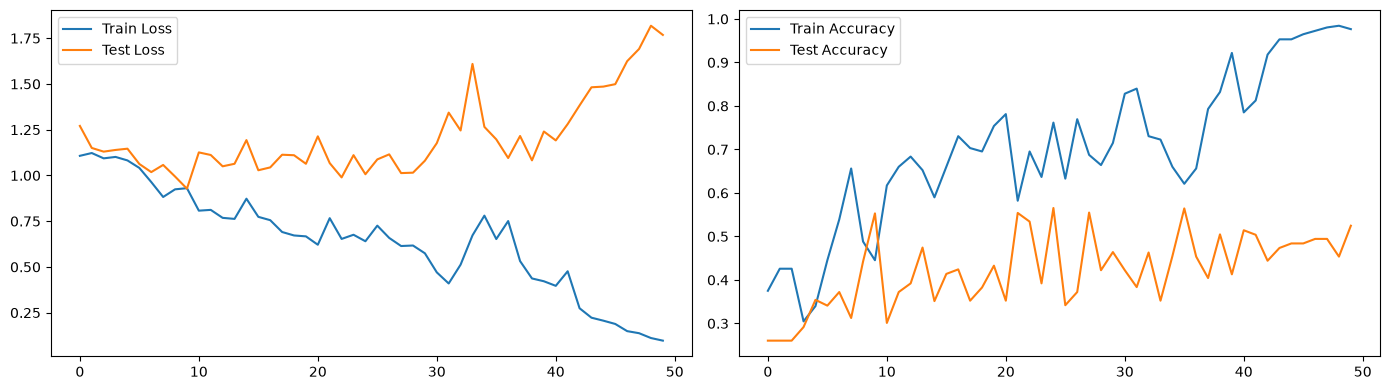

In [ ]:

plt.figure(figsize=(14,4))

plt.subplot(1, 2, 1)
plt.plot(result['train_loss'], label="Train Loss")
plt.plot(result['test_loss'], label = "Test Loss")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(result['train_acc'], label="Train Accuracy")
plt.plot(result['test_acc'], label = "Test Accuracy")
plt.legend()

plt.tight_layout()

plt.show()

## 6. Double the number of hidden units in your model and train it for 20 epochs, what happens to the results?

In [77]:
# Double the number of hidden units and train for 20 epochs
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_1 = ModifiedTinyVGG(
    in_channels=3,
    hidden_units=20,
    output_units=len(class_names)
)

In [79]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model_1.parameters(), 
                             lr=0.001)

In [81]:
result = train(
    model_1,
    train_dataloader,
    test_dataloader,
    optimizer,
    loss_fn,
    epochs=20,
)

  0%|          | 0/20 [00:00<?, ?it/s]

Train Loss: 1.00 | Train Accuracy:  57.42%


  5%|▌         | 1/20 [00:01<00:33,  1.78s/it]

Test Loss: 1.09 | Test Accuracy:  39.30%
Epoch: 1 | train_loss: 1.0005 | train_acc: 0.5742 | test_loss: 1.0934 | test_acc: 0.3930
Train Loss: 1.02 | Train Accuracy:  41.41%


 10%|█         | 2/20 [00:03<00:28,  1.59s/it]

...

Test Loss: 2.02 | Test Accuracy:  53.31%
Epoch: 18 | train_loss: 0.1444 | train_acc: 0.9844 | test_loss: 2.0207 | test_acc: 0.5331
Train Loss: 0.12 | Train Accuracy:  94.14%


 95%|█████████▌| 19/20 [00:26<00:01,  1.37s/it]

Test Loss: 2.86 | Test Accuracy:  29.17%
Epoch: 19 | train_loss: 0.1213 | train_acc: 0.9414 | test_loss: 2.8559 | test_acc: 0.2917
Train Loss: 0.07 | Train Accuracy:  96.48%


100%|██████████| 20/20 [00:28<00:00,  1.41s/it]

Test Loss: 2.21 | Test Accuracy:  52.46%
Epoch: 20 | train_loss: 0.0743 | train_acc: 0.9648 | test_loss: 2.2069 | test_acc: 0.5246


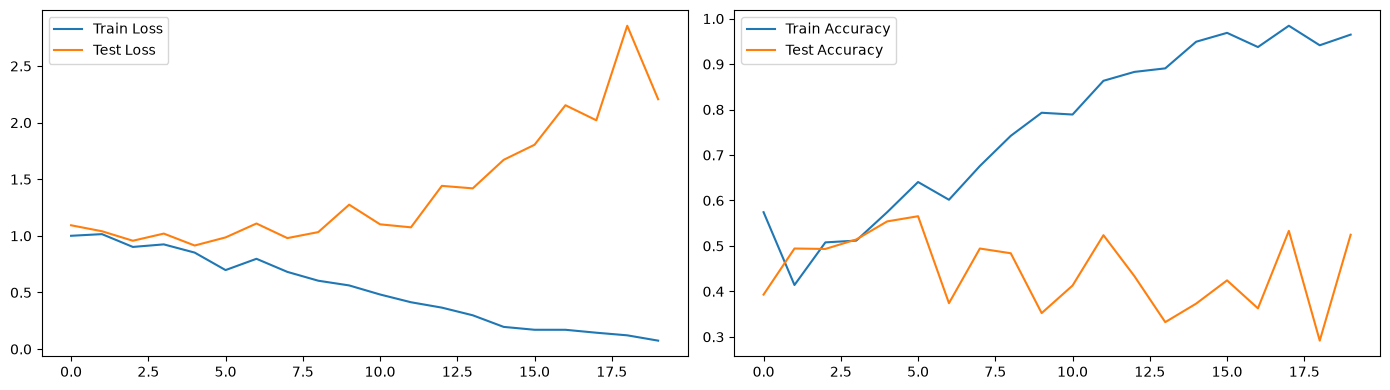

In [82]:

plt.figure(figsize=(14,4))

plt.subplot(1, 2, 1)
plt.plot(result['train_loss'], label="Train Loss")
plt.plot(result['test_loss'], label = "Test Loss")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(result['train_acc'], label="Train Accuracy")
plt.plot(result['test_acc'], label = "Test Accuracy")
plt.legend()

plt.tight_layout()

plt.show()

It looks like the model is still overfitting, even when changing the number of hidden units.

To fix this, we'd have to look at ways to prevent overfitting with our model.

## 7. Double the data you're using with your model from step 6 and train it for 20 epochs, what happens to the results?
* **Note:** You can use the [custom data creation notebook](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/04_custom_data_creation.ipynb) to scale up your Food101 dataset.
* You can also find the [already formatted double data (20% instead of 10% subset) dataset on GitHub](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/data/pizza_steak_sushi_20_percent.zip), you will need to write download code like in exercise 2 to get it into this notebook.

In [85]:
# Download 20% data for Pizza/Steak/Sushi from GitHub
import requests
import zipfile
from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"

# If the image folder doesn't exist, download it and prepare it... 
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)
    
# Download pizza, steak, sushi data
with open(data_path / "pizza_steak_sushi_20_percent.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
    print("Downloading pizza, steak, sushi 20% data...")
    f.write(request.content)

# Unzip pizza, steak, sushi data
with zipfile.ZipFile(data_path / "pizza_steak_sushi_20_percent.zip", "r") as zip_ref:
    print("Unzipping pizza, steak, sushi 20% data...") 
    zip_ref.extractall(image_path)

data/pizza_steak_sushi_20_percent directory exists.


KeyboardInterrupt: 

In [86]:
# See how many images we have
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data/pizza_steak_sushi_20_percent'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi_20_percent/train'.
There are 0 directories and 154 images in 'data/pizza_steak_sushi_20_percent/train/pizza'.
There are 0 directories and 146 images in 'data/pizza_steak_sushi_20_percent/train/steak'.
There are 0 directories and 150 images in 'data/pizza_steak_sushi_20_percent/train/sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi_20_percent/test'.
There are 0 directories and 46 images in 'data/pizza_steak_sushi_20_percent/test/pizza'.
There are 0 directories and 58 images in 'data/pizza_steak_sushi_20_percent/test/steak'.
There are 0 directories and 46 images in 'data/pizza_steak_sushi_20_percent/test/sushi'.


Excellent, we now have double the training and testing images... 

In [87]:
# Create the train and test paths
train_data_20_percent_path = image_path / "train"
test_data_20_percent_path = image_path / "test"

train_data_20_percent_path, test_data_20_percent_path

(PosixPath('data/pizza_steak_sushi_20_percent/train'),
 PosixPath('data/pizza_steak_sushi_20_percent/test'))

In [88]:
# Turn the 20 percent datapaths into Datasets and DataLoaders
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader

simple_transform = transforms.Compose([
  transforms.Resize((128, 128)),                                     
  transforms.ToTensor()
])

# Create datasets

train_data = ImageFolder(
    root = train_data_20_percent_path,
    transform = simple_transform,
)

test_data = ImageFolder(
    root = test_data_20_percent_path,
    transform = simple_transform
)

# Create dataloaders

train_dataloader = DataLoader(
    dataset = train_data,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count() or 0,
    shuffle = True
)


test_dataloader = DataLoader(
    dataset = test_data,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count() or 0,
)


In [93]:
# Train a model with increased amount of data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_2 = ModifiedTinyVGG(
    in_channels = 3,
    hidden_units = 16,
    output_units = len(class_names)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params = model_2.parameters(),
    lr = 0.001
)

result = train(
    model_2,
    train_dataloader,
    test_dataloader,
    optimizer,
    loss_fn,
    epochs=20

)

  0%|          | 0/20 [00:00<?, ?it/s]

Train Loss: 1.12 | Train Accuracy:  28.96%


  5%|▌         | 1/20 [00:02<00:41,  2.21s/it]

Test Loss: 1.08 | Test Accuracy:  45.06%
Epoch: 1 | train_loss: 1.1230 | train_acc: 0.2896 | test_loss: 1.0784 | test_acc: 0.4506
Train Loss: 1.02 | Train Accuracy:  51.88%


 10%|█         | 2/20 [00:04<00:35,  2.00s/it]

...

Test Loss: 1.15 | Test Accuracy:  58.35%
Epoch: 18 | train_loss: 0.2242 | train_acc: 0.9146 | test_loss: 1.1480 | test_acc: 0.5835
Train Loss: 0.16 | Train Accuracy:  95.42%


 95%|█████████▌| 19/20 [00:32<00:01,  1.66s/it]

Test Loss: 1.31 | Test Accuracy:  63.41%
Epoch: 19 | train_loss: 0.1566 | train_acc: 0.9542 | test_loss: 1.3113 | test_acc: 0.6341
Train Loss: 0.12 | Train Accuracy:  97.08%


100%|██████████| 20/20 [00:33<00:00,  1.69s/it]

Test Loss: 1.48 | Test Accuracy:  61.59%
Epoch: 20 | train_loss: 0.1213 | train_acc: 0.9708 | test_loss: 1.4771 | test_acc: 0.6159


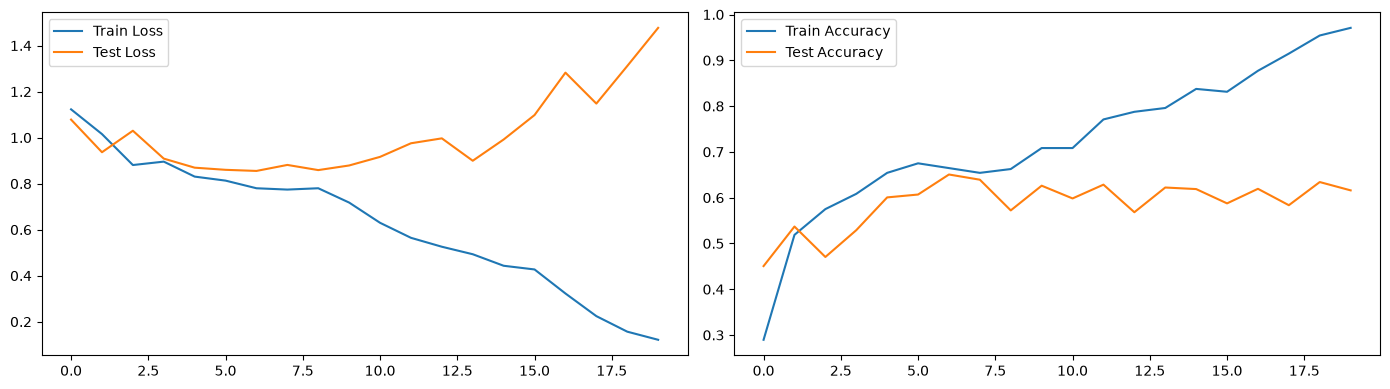

In [94]:

plt.figure(figsize=(14,4))

plt.subplot(1, 2, 1)
plt.plot(result['train_loss'], label="Train Loss")
plt.plot(result['test_loss'], label = "Test Loss")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(result['train_acc'], label="Train Accuracy")
plt.plot(result['test_acc'], label = "Test Accuracy")
plt.legend()

plt.tight_layout()

plt.show()

## 8. Make a prediction on your own custom image of pizza/steak/sushi (you could even download one from the internet) with your trained model from exercise 7 and share your prediction. 
* Does the model you trained in exercise 7 get it right? 
* If not, what do you think you could do to improve it?

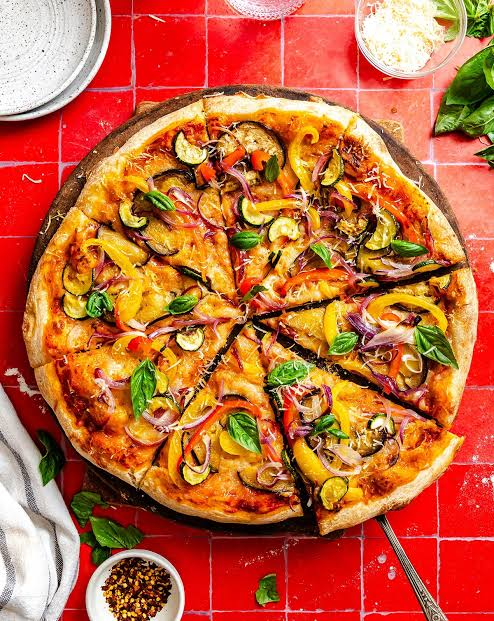

In [95]:
image_path = Path() / 'data' / 'pizza.jpeg'

Image.open(image_path)

In [96]:
img = simple_transform(Image.open(image_path))

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

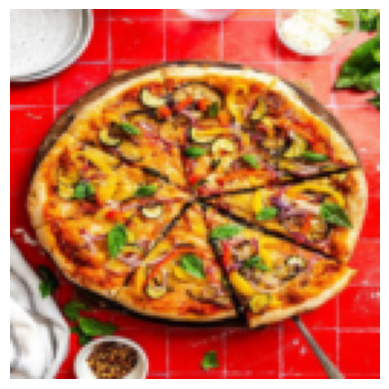

In [99]:
plt.imshow(img.permute(1, 2, 0))
plt.axis(False)

In [109]:
class_names[torch.argmax(model_2(img.unsqueeze(dim=0).to(device)))]

'pizza'

It answerd right tho I still think that the training data is still small and we need way more to get better result